In [2]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as spt
import sys
import os
import time
import h5py
from Calculate_p3ds import get_box_geometry, measure_p3d_Mpc

# One minibox

This is just to show how the Calculate_p3d.py script works. For that reason we will only use one minibox instead of the whole simulation box

In [2]:
filename = '/data/desi/scratch/lfloresl/astrid_hcd_outputs/Deltas/deltas_0.3_21.3/minibox_00.hdf5'
with h5py.File(filename, 'r') as f:
            
        # Atributes
        logNHi_min = f.attrs['logNHI_min']
        logNHi_max = f.attrs['logNHI_max']
        smth_factor = f.attrs['Smoothing factor']
        Lbox = f.attrs['box_size_Mpch']
        Lmbox = f.attrs['minibox_size_Mpch']
        Nsk = f.attrs['skewers_per_side']
        Np = f.attrs['pixels_per_skewer']
        Pw = f.attrs['pixel_width_Mpch']
        Ssk = f.attrs['skewer_separation_Mpch']

        # Data
        delta_tot = f['deltas/delta_tot'][:]
        delta_hcd = f['deltas/delta_hcd'][:]
        delta_lya = f['deltas/delta_lya'][:]
    
        C = f['C'][()] 
        colden = f['Colden'][:]
        mask = f['Mask'][:]

delta_lyahcd = delta_lya*delta_hcd

In [25]:
# ASTRID cosmology values
hubble, z = 0.6774, 2.5

In [26]:
box = get_box_geometry(delta_tot, Lbox/hubble)

n_xy=100, n_z=2500


In [27]:
results_tot = measure_p3d_Mpc(delta_tot, delta_tot, z, box, 
                              n_k_bins=20, k_Mpc_max=4, n_mu_bins=10, mask=mask)
results_lya = measure_p3d_Mpc(delta_lya, delta_lya, z, box, 
                              n_k_bins=20, k_Mpc_max=4, n_mu_bins=10, mask=mask)
results_hcd = measure_p3d_Mpc(delta_hcd, delta_hcd, z, box, 
                              n_k_bins=20, k_Mpc_max=4, n_mu_bins=10, mask=mask)
results_lyahcd = measure_p3d_Mpc(delta_lya, delta_hcd, z, box, 
                              n_k_bins=20, k_Mpc_max=4, n_mu_bins=10, mask=mask)
results_3lya = measure_p3d_Mpc(delta_lyahcd, delta_lya, z, box, 
                              n_k_bins=20, k_Mpc_max=4, n_mu_bins=10, mask=mask)
results_3hcd = measure_p3d_Mpc(delta_lyahcd, delta_hcd, z, box, 
                              n_k_bins=20, k_Mpc_max=4, n_mu_bins=10, mask=mask)
results_4 = measure_p3d_Mpc(delta_lyahcd, delta_lyahcd, z, box, 
                              n_k_bins=20, k_Mpc_max=4, n_mu_bins=10, mask=mask)
del delta_tot, delta_lya, delta_hcd, delta_lyahcd

Masking applied
Masking applied
Masking applied
Masking applied
Masking applied
Masking applied
Masking applied


In [28]:
p3d_tot = np.array(results_tot['p3d_Mpc'])
k = np.array(results_tot['k_Mpc'])
mu_bins = np.array(results_tot['mu_bin_edges'])
mu_center = np.array(results_tot['mu_center'])
p3d_lya = np.array(results_lya['p3d_Mpc'])
p3d_hcd = np.array(results_hcd['p3d_Mpc'])
p3d_lyahcd = np.array(results_lyahcd['p3d_Mpc'])
p3d_3lya = np.array(results_3lya['p3d_Mpc'])
p3d_3hcd = np.array(results_3hcd['p3d_Mpc'])
p3d_4 = np.array(results_4['p3d_Mpc'])
raw_p3d_tot = np.array(results_tot['p3d_raw'])

In [29]:
p3d_34 = 2*p3d_3lya + 2*p3d_3hcd + p3d_4 - C**2
p3d_model = (p3d_lya + p3d_hcd + 2*p3d_lyahcd + p3d_34)/((1+C)**2)

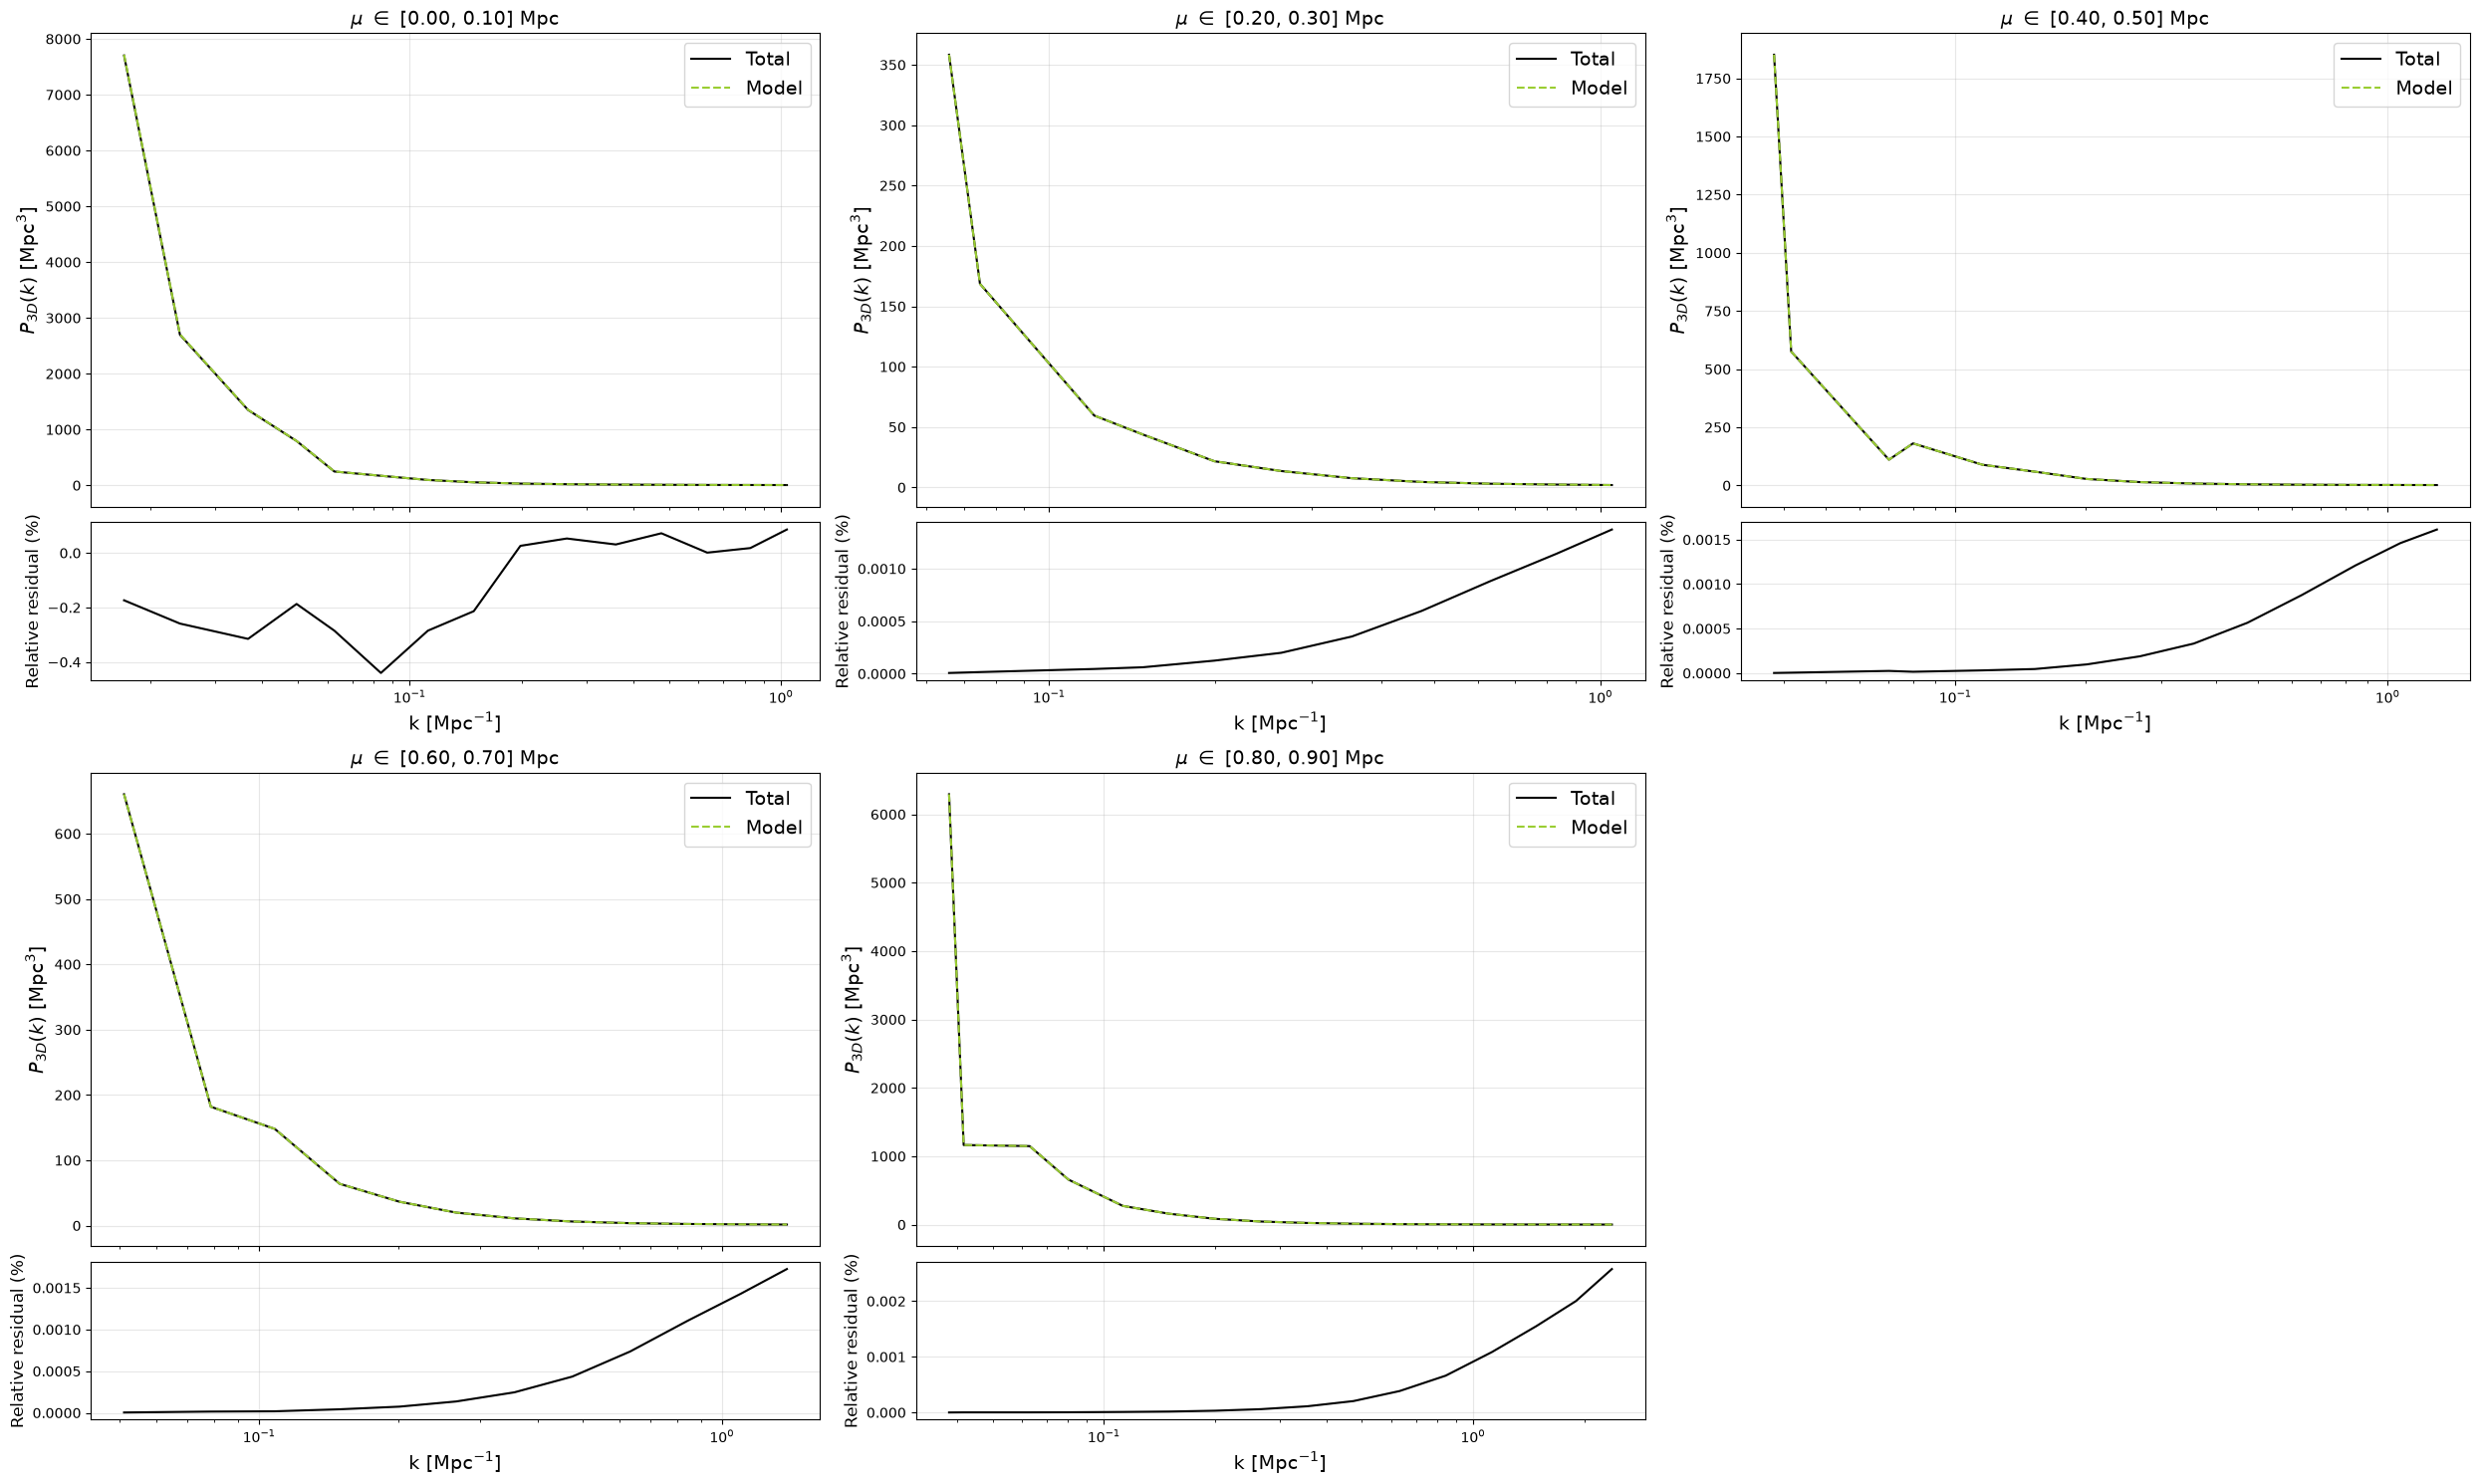

In [40]:
fig = plt.figure(figsize=(25, 15))
outer = fig.add_gridspec(2, 3)

for panel, i in enumerate(range(0, len(mu_center), 2)):
    inner = outer[panel].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.05)
    ax_main = fig.add_subplot(inner[0])
    ax_res = fig.add_subplot(inner[1], sharex=ax_main)

    mask = ~np.isnan(k[:, i])
    # ---------------- MAIN ----------------
    ax_main.plot(k[:, i][mask], p3d_tot[:, i][mask], color='k', label='Total')
    #ax_main.fill_between(k, Px_tot[i] - Px_std_tot[i], Px_tot[i] + Px_std_tot[i], color='k', alpha=0.15)
    ax_main.plot(k[:, i][mask], p3d_model[:, i][mask], linestyle='--', color='yellowgreen', label='Model')

    ax_main.set_xscale('log')
    ax_main.grid(alpha=0.3)
    ax_main.legend(fontsize=14)
    ax_main.set_ylabel(r'$P_{3D}(k)$ [Mpc$^3$]', fontsize=14)
    ax_main.set_title(r'$\mu$ $\in$ [%.2f, %.2f] Mpc' % (mu_bins[i], mu_bins[i+1]), fontsize=14)
    ax_main.tick_params(labelbottom=False)

    # ---------------- RESIDUAL ----------------
    ax_res.plot(k[:, i][mask], (p3d_tot[:, i][mask] - p3d_model[:, i][mask])/p3d_tot[:, i][mask]*100, color='k')

    ax_res.set_xscale('log')
    ax_res.grid(alpha=0.3)
    ax_res.set_xlabel(r'k [Mpc$^{-1}$]', fontsize=14)
    ax_res.set_ylabel('Relative residual (%)', fontsize=12)
    #if i != 0:
        #ax_res.set_ylim(-0.001, 0.001)

plt.tight_layout()
plt.savefig('plot.png', dpi=200, bbox_inches='tight')

Great! So now that we know this works, we will measure using the full ASTRID simulation box. We cannot split into different miniboxes because the maximum separation between points will be different than in the full box (now the plane xy is taken into account) than in the miniboxes. In the latter, large k modes will not be measured, so we will see an underestimation with respect to the real measurement.

# Reading ASTRID output file

We will read the whole box (no division into miniboxes) p3d output

In [3]:
data = '/data/desi/scratch/lfloresl/astrid_hcd_outputs/p3ds_0.3_21.3_fullbox.hdf5'

with h5py.File(data, 'r') as f:
    print('Atributes:')
    for m in f.attrs.keys():
        print(f'{m} = {f.attrs[m]}')
    print('----------------') 
    print('Data:')
    print(f.keys())
    k = f['k'][:]
    print('k shape:', k.shape)
    mu_bins = f['mu_bins'][:]
    mu_center = f['mu_center'][:]
    mu = f['mu'][:]
    print('mu shape:', mu.shape)
    C = f['C'][()]
    
    P3d_tot = f['p3ds/p3d_tot'][:]
    print('p3ds_tot shape:', P3d_tot.shape)
    P3d_lya = f['p3ds/p3d_lya'][:]
    print('p3ds_lya shape:', P3d_lya.shape)
    P3d_hcd = f['p3ds/p3d_hcd'][:]
    print('p3ds_hcd shape:', P3d_hcd.shape)
    P3d_lyahcd = f['p3ds/p3d_lyahcd'][:]
    print('p3ds_lyahcd shape:', P3d_lyahcd.shape)
    P3d_3lya = f['p3ds/p3d_3lya'][:]
    print('p3ds_3lya shape:', P3d_3lya.shape)
    P3d_3hcd = f['p3ds/p3d_3hcd'][:]
    print('p3ds_3hcd shape:', P3d_3hcd.shape)
    P3d_4 = f['p3ds/p3d_4'][:]
    print('p3ds_4 shape:', P3d_4.shape)
    
    counts_tot = f['counts/counts_tot'][:]
    print('counts_tot shape:', counts_tot.shape)
    counts_lya = f['counts/counts_lya'][:]
    print('counts_lya shape:', counts_lya.shape)
    counts_hcd = f['counts/counts_hcd'][:]
    print('counts_hcd shape:', counts_hcd.shape)
    counts_lyahcd = f['counts/counts_lyahcd'][:]
    print('counts_lyahcd shape:', counts_lyahcd.shape)
    counts_3lya = f['counts/counts_3lya'][:]
    print('counts_3lya shape:', counts_3lya.shape)
    counts_3hcd = f['counts/counts_3hcd'][:]
    print('counts_3hcd shape:', counts_3hcd.shape)
    counts_4 = f['counts/counts_4'][:]
    print('counts_4 shape:', counts_4.shape)

Atributes:
Box_size_Mpch = 250
Smoothing factor = 0.3
logNHI_max = 21.3
logNHI_min = 0
pixel_width_Mpch = 0.1
pixels_per_skewer = 2500
skewer_separation_Mpch = 0.5
skewers_per_boxside = 500
----------------
Data:
<KeysViewHDF5 ['C', 'counts', 'k', 'mu', 'mu_bins', 'mu_center', 'p3ds']>
k shape: (20, 10)
mu shape: (20, 10)
p3ds_tot shape: (20, 10)
p3ds_lya shape: (20, 10)
p3ds_hcd shape: (20, 10)
p3ds_lyahcd shape: (20, 10)
p3ds_3lya shape: (20, 10)
p3ds_3hcd shape: (20, 10)
p3ds_4 shape: (20, 10)
counts_tot shape: (20, 10)
counts_lya shape: (20, 10)
counts_hcd shape: (20, 10)
counts_lyahcd shape: (20, 10)
counts_3lya shape: (20, 10)
counts_3hcd shape: (20, 10)
counts_4 shape: (20, 10)


In [4]:
P3d_34 = 2*P3d_3lya + 2*P3d_3hcd + P3d_4 - C**2
P3d_model = (P3d_lya + P3d_hcd + 2*P3d_lyahcd + P3d_34)/((1+C)**2)

In [5]:
P3d_std_tot = P3d_tot/np.sqrt(counts_tot)
P3d_std_lya = P3d_lya/np.sqrt(counts_lya)
P3d_std_hcd = P3d_hcd/np.sqrt(counts_hcd)
P3d_std_lyahcd = P3d_lyahcd/np.sqrt(counts_lyahcd)
P3d_std_3lya = P3d_3lya/np.sqrt(counts_3lya)
P3d_std_3hcd = P3d_3hcd/np.sqrt(counts_3hcd)
P3d_std_4 = P3d_4/np.sqrt(counts_4)

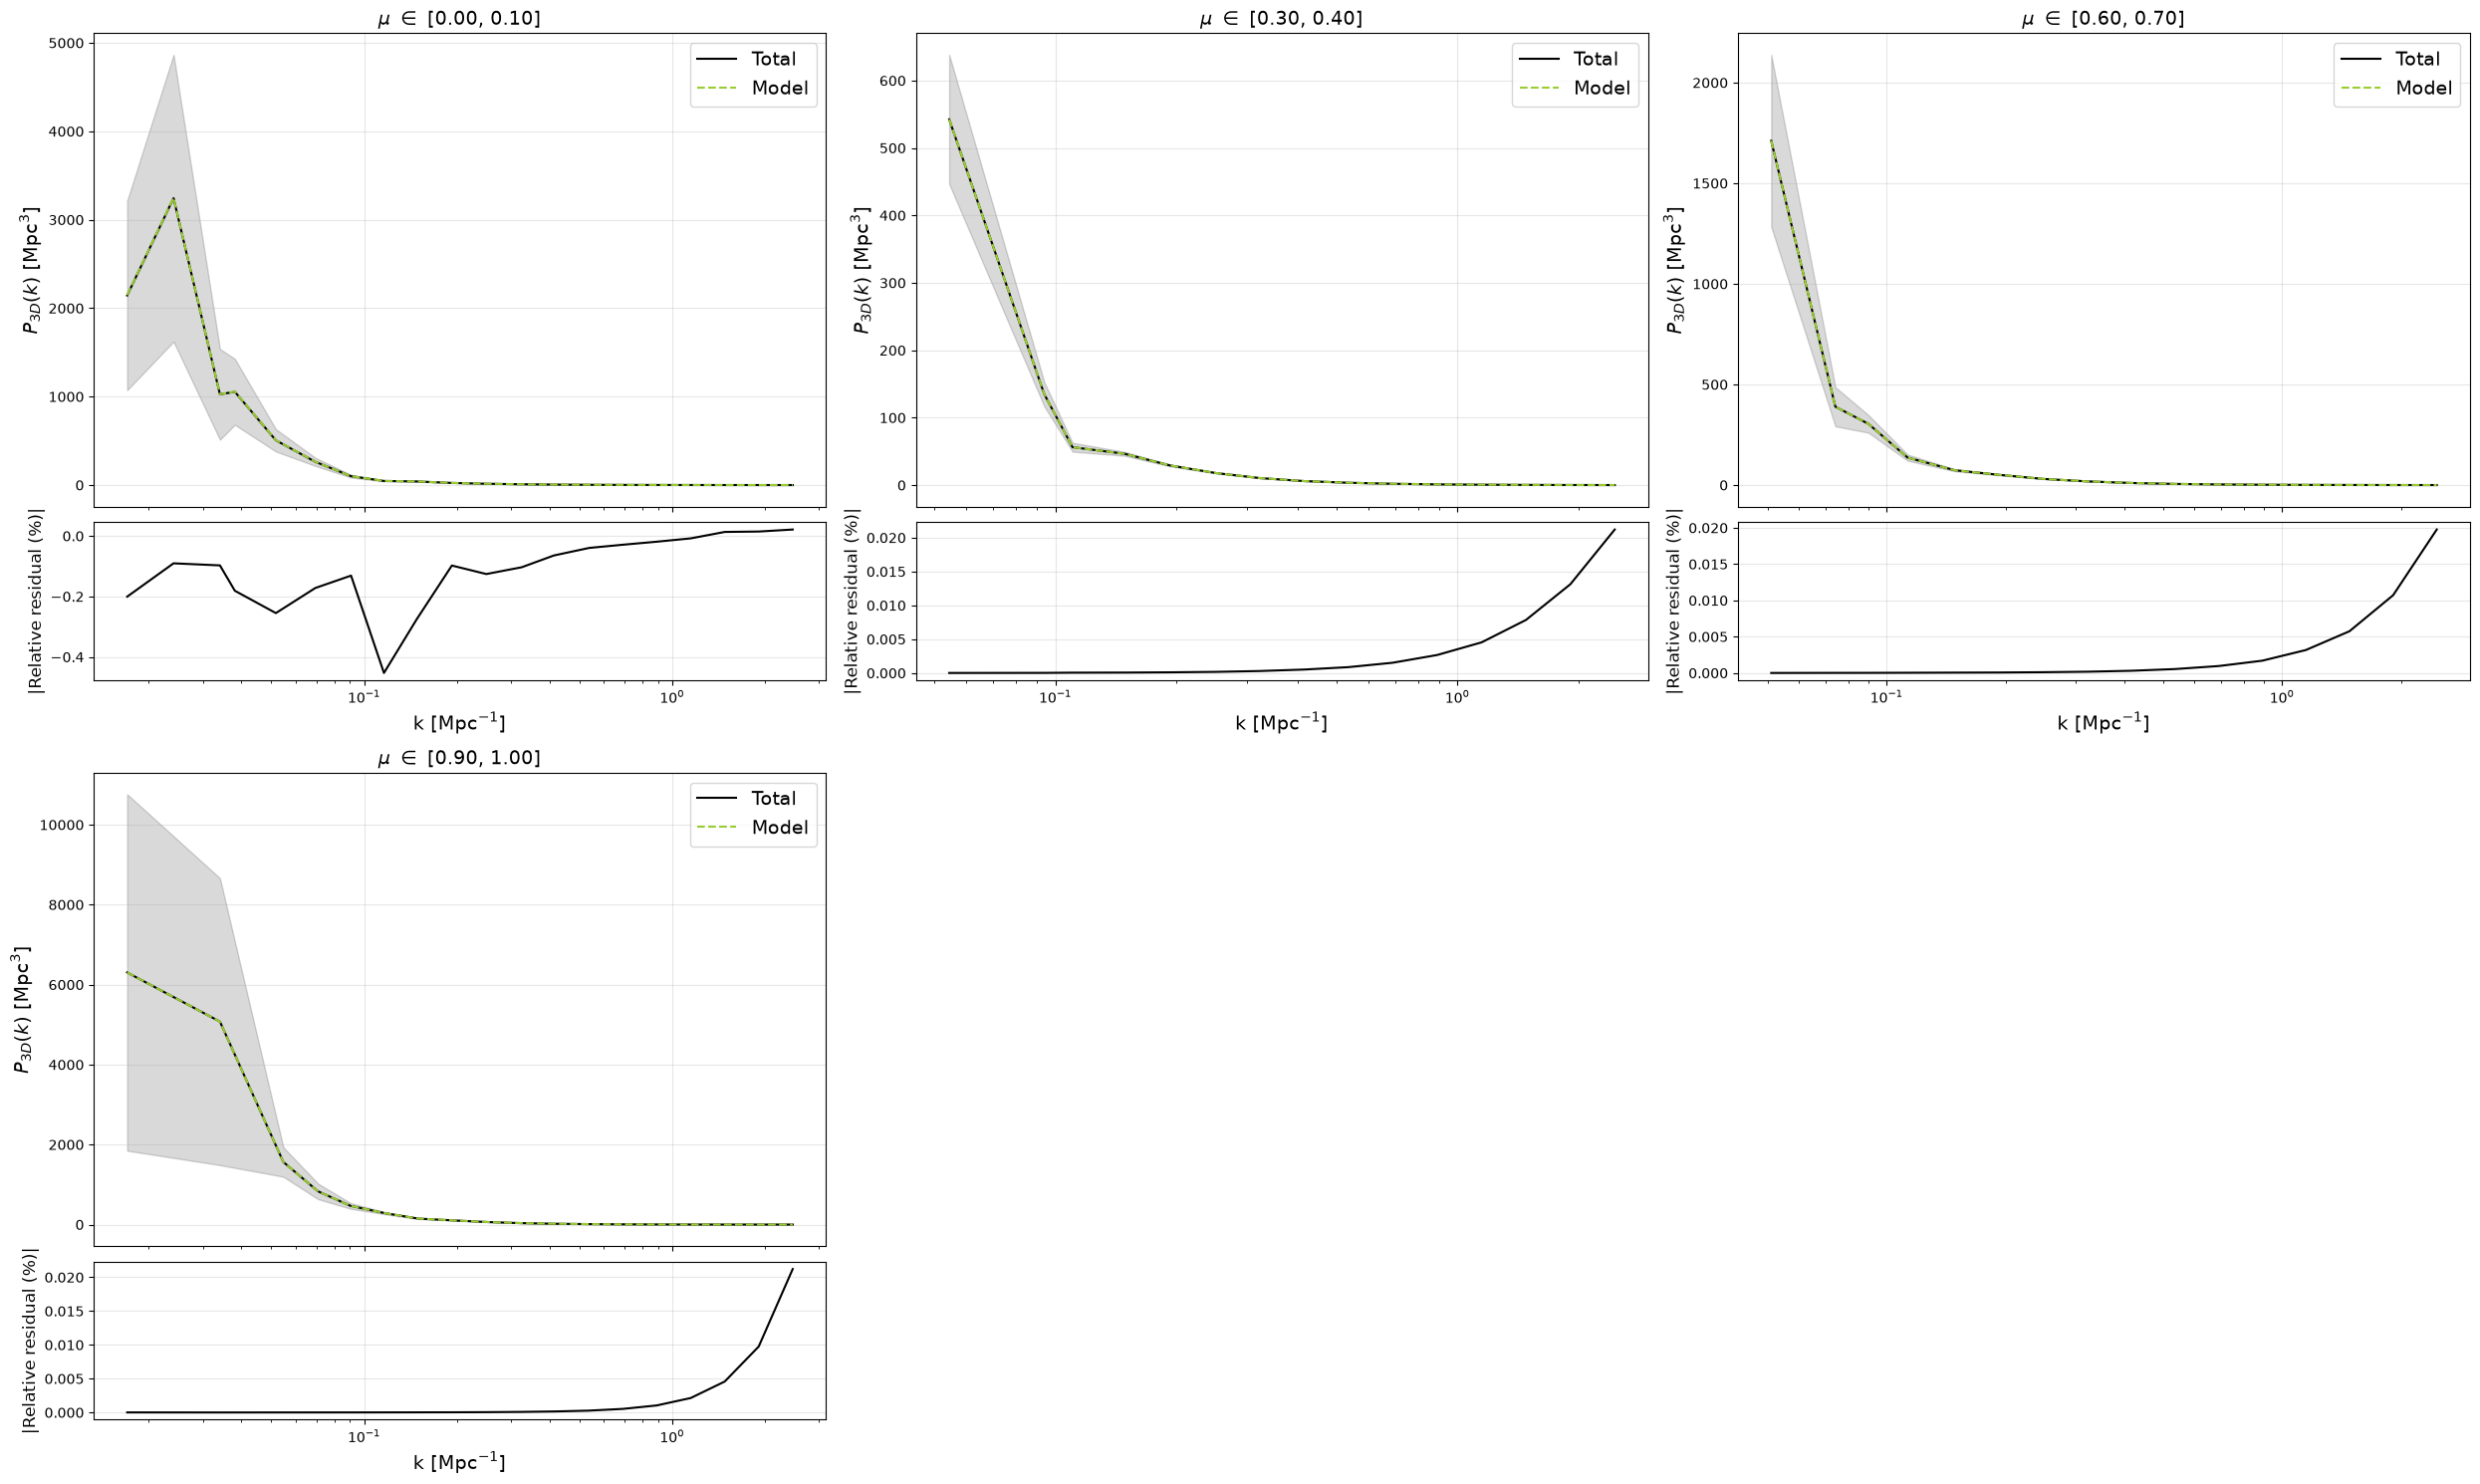

In [11]:
fig = plt.figure(figsize=(25, 15))
outer = fig.add_gridspec(2, 3)

for panel, i in enumerate(range(0, len(mu_center), 3)):
    inner = outer[panel].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.05)
    ax_main = fig.add_subplot(inner[0])
    ax_res = fig.add_subplot(inner[1], sharex=ax_main)

    mask = ~np.isnan(k[:, i])
    # ---------------- MAIN ----------------
    ax_main.plot(k[:, i][mask], P3d_tot[:, i][mask], color='k', label='Total')
    ax_main.fill_between(k[:, i][mask], P3d_tot[:, i][mask] - P3d_std_tot[:, i][mask], P3d_tot[:, i][mask] + P3d_std_tot[:, i][mask], color='k', alpha=0.15)
    ax_main.plot(k[:, i][mask], P3d_model[:, i][mask], linestyle='--', color='yellowgreen', label='Model')

    ax_main.set_xscale('log')
    ax_main.grid(alpha=0.3)
    ax_main.legend(fontsize=14)
    ax_main.set_ylabel(r'$P_{3D}(k)$ [Mpc$^3$]', fontsize=14)
    ax_main.set_title(r'$\mu$ $\in$ [%.2f, %.2f]' % (mu_bins[i], mu_bins[i+1]), fontsize=14)
    ax_main.tick_params(labelbottom=False)

    # ---------------- RESIDUAL ----------------
    ax_res.plot(k[:, i][mask], (P3d_tot[:, i][mask] - P3d_model[:, i][mask])/P3d_tot[:, i][mask]*100, color='k')

    ax_res.set_xscale('log')
    ax_res.grid(alpha=0.3)
    ax_res.set_xlabel(r'k [Mpc$^{-1}$]', fontsize=14)
    ax_res.set_ylabel('|Relative residual (%)|', fontsize=12)

plt.tight_layout()
plt.savefig('plot.png', dpi=200, bbox_inches='tight')

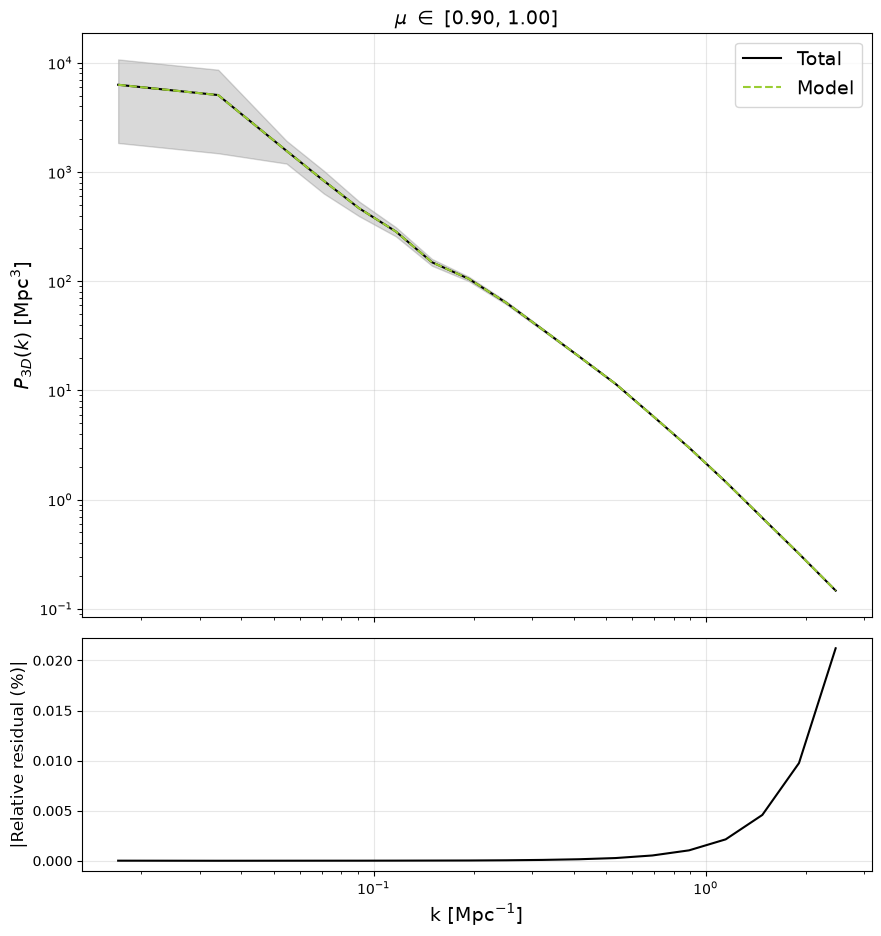

In [18]:
fig = plt.figure(figsize=(25, 18))

i = 9
gs = plt.GridSpec(2, 3)[0]
inner = gs.subgridspec(2, 1, height_ratios=[2.5, 1], hspace=0.05)
ax_main = fig.add_subplot(inner[0])
ax_res = fig.add_subplot(inner[1], sharex=ax_main)

mask = ~np.isnan(k[:, i])
# ---------------- MAIN ----------------
ax_main.plot(k[:, i][mask], P3d_tot[:, i][mask], color='k', label='Total')
ax_main.fill_between(k[:, i][mask], P3d_tot[:, i][mask] - P3d_std_tot[:, i][mask], P3d_tot[:, i][mask] + P3d_std_tot[:, i][mask], color='k', alpha=0.15)
ax_main.plot(k[:, i][mask], P3d_model[:, i][mask], linestyle='--', color='yellowgreen', label='Model')

ax_main.set_xscale('log')
ax_main.set_yscale('log')
ax_main.grid(alpha=0.3)
ax_main.legend(fontsize=14)
ax_main.set_ylabel(r'$P_{3D}(k)$ [Mpc$^3$]', fontsize=14)
ax_main.set_title(r'$\mu$ $\in$ [%.2f, %.2f]' % (mu_bins[i], mu_bins[i+1]), fontsize=14)
ax_main.tick_params(labelbottom=False)

# ---------------- RESIDUAL ----------------
ax_res.plot(k[:, i][mask], (P3d_tot[:, i][mask] - P3d_model[:, i][mask])/P3d_tot[:, i][mask]*100, color='k')
 
ax_res.set_xscale('log')
ax_res.grid(alpha=0.3)
ax_res.set_xlabel(r'k [Mpc$^{-1}$]', fontsize=14)
ax_res.set_ylabel('|Relative residual (%)|', fontsize=12)

plt.tight_layout()
plt.savefig('images/p3d_sum.png', dpi=200, bbox_inches='tight')

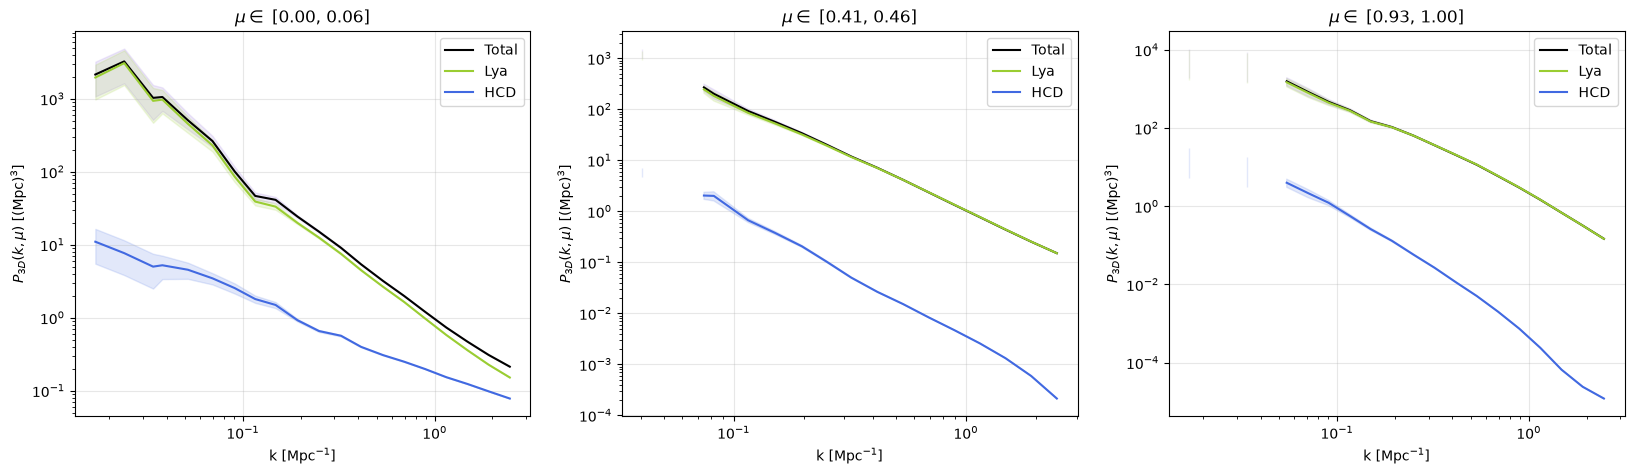

In [11]:
plt.figure(figsize=(20, 5))

for idx, i in enumerate([0, 4, 9]):
    plt.subplot(1, 3, idx+1)
    plt.plot(k[:, i], P3d_tot[:, i], color='k', label='Total')
    plt.fill_between(k[:, i], (P3d_tot[:, i]-P3d_std_tot[:, i]), (P3d_tot[:, i]+P3d_std_tot[:, i]), color='mediumpurple', alpha=0.15)
    plt.plot(k[:, i], P3d_lya[:, i], color='yellowgreen', label='Lya')
    plt.fill_between(k[:, i], (P3d_lya[:, i]-P3d_std_lya[:, i]), (P3d_lya[:, i]+P3d_std_lya[:, i]), color='yellowgreen', alpha=0.15)
    plt.plot(k[:, i], P3d_hcd[:, i], color='royalblue', label='HCD')
    plt.fill_between(k[:, i], (P3d_hcd[:, i]-P3d_std_hcd[:, i]), (P3d_hcd[:, i]+P3d_std_hcd[:, i]), color='royalblue', alpha=0.15)
    plt.xscale('log')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.yscale('log')
    plt.xlabel(r'k [Mpc$^{-1}$]')
    plt.ylabel(r'$P_{3D}(k, \mu)$ [(Mpc)$^3$]')
    plt.title(r'$\mu \in$ [%.2f, %.2f]' %(np.nanmin(mu[:, i]), np.nanmax(mu[:, i])));

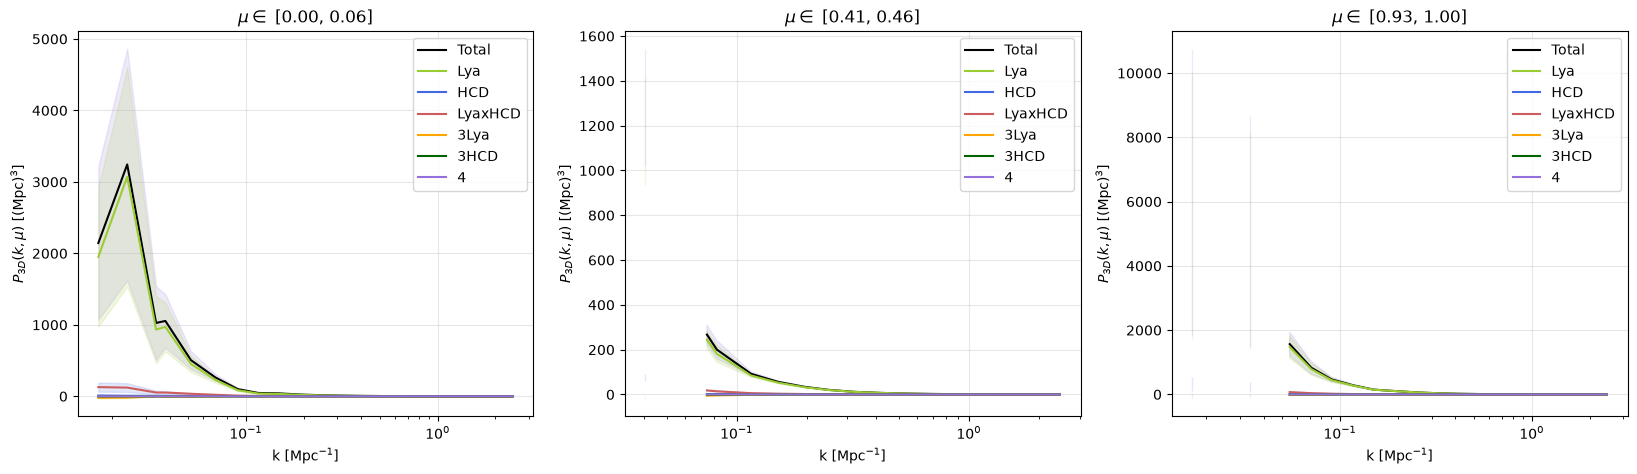

In [12]:
plt.figure(figsize=(20, 5))

for idx, i in enumerate([0, 4, 9]):
    plt.subplot(1, 3, idx+1)
    plt.plot(k[:, i], P3d_tot[:, i], color='k', label='Total')
    plt.fill_between(k[:, i], (P3d_tot[:, i]-P3d_std_tot[:, i]), (P3d_tot[:, i]+P3d_std_tot[:, i]), color='mediumpurple', alpha=0.15)
    plt.plot(k[:, i], P3d_lya[:, i], color='yellowgreen', label='Lya')
    plt.fill_between(k[:, i], (P3d_lya[:, i]-P3d_std_lya[:, i]), (P3d_lya[:, i]+P3d_std_lya[:, i]), color='yellowgreen', alpha=0.15)
    plt.plot(k[:, i], P3d_hcd[:, i], color='royalblue', label='HCD')
    plt.fill_between(k[:, i], (P3d_hcd[:, i]-P3d_std_hcd[:, i]), (P3d_hcd[:, i]+P3d_std_hcd[:, i]), color='royalblue', alpha=0.15)
    plt.plot(k[:, i], P3d_lyahcd[:, i], color='indianred', label='LyaxHCD')
    plt.fill_between(k[:, i], (P3d_lyahcd[:, i]-P3d_std_lyahcd[:, i]), (P3d_lyahcd[:, i]+P3d_std_lyahcd[:, i]), color='royalblue', alpha=0.15)
    plt.plot(k[:, i], P3d_3lya[:, i], color='orange', label='3Lya')
    plt.fill_between(k[:, i], (P3d_3lya[:, i]-P3d_std_3lya[:, i]), (P3d_3lya[:, i]+P3d_std_3lya[:, i]), color='yellowgreen', alpha=0.15)
    plt.plot(k[:, i], P3d_3hcd[:, i], color='darkgreen', label='3HCD')
    plt.fill_between(k[:, i], (P3d_3hcd[:, i]-P3d_std_3hcd[:, i]), (P3d_3hcd[:, i]+P3d_std_3hcd[:, i]), color='royalblue', alpha=0.15)
    plt.plot(k[:, i], P3d_4[:, i], color='mediumpurple', label='4')
    plt.fill_between(k[:, i], (P3d_4[:, i]-P3d_std_4[:, i]), (P3d_4[:, i]+P3d_std_4[:, i]), color='royalblue', alpha=0.15)

    plt.xscale('log')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.xlabel(r'k [Mpc$^{-1}$]')
    plt.ylabel(r'$P_{3D}(k, \mu)$ [(Mpc)$^3$]')
    plt.title(r'$\mu \in$ [%.2f, %.2f]' %(np.nanmin(mu[:, i]), np.nanmax(mu[:, i])));

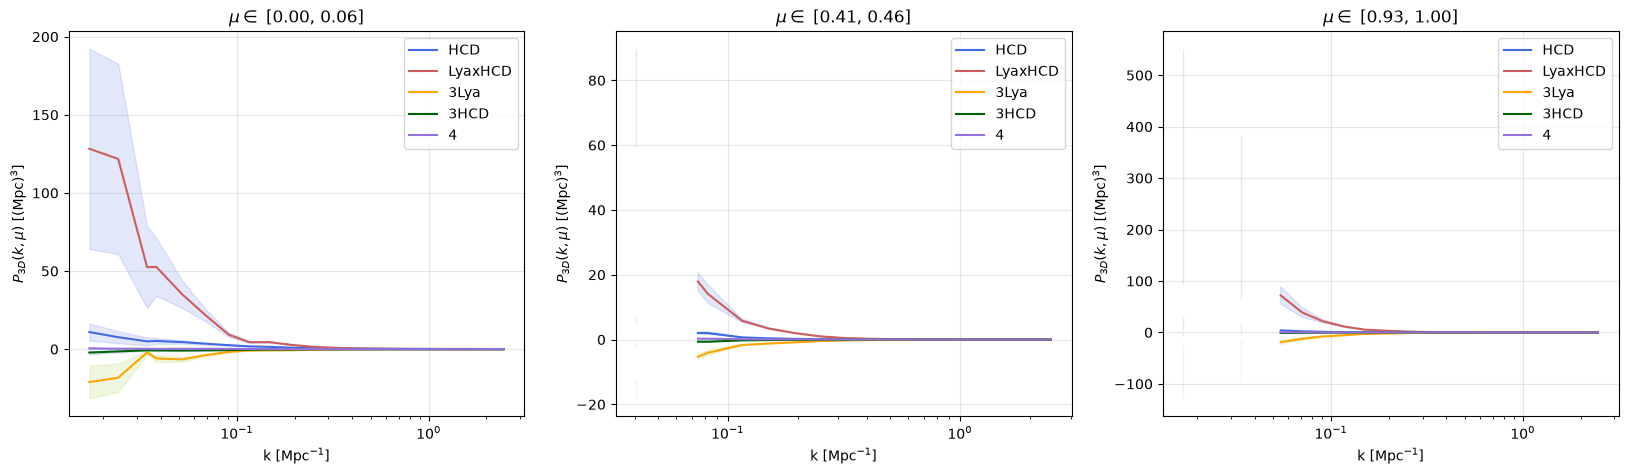

In [13]:
plt.figure(figsize=(20, 5))

for idx, i in enumerate([0, 4, 9]):
    plt.subplot(1, 3, idx+1)
    plt.plot(k[:, i], P3d_hcd[:, i], color='royalblue', label='HCD')
    plt.fill_between(k[:, i], (P3d_hcd[:, i]-P3d_std_hcd[:, i]), (P3d_hcd[:, i]+P3d_std_hcd[:, i]), color='royalblue', alpha=0.15)
    plt.plot(k[:, i], P3d_lyahcd[:, i], color='indianred', label='LyaxHCD')
    plt.fill_between(k[:, i], (P3d_lyahcd[:, i]-P3d_std_lyahcd[:, i]), (P3d_lyahcd[:, i]+P3d_std_lyahcd[:, i]), color='royalblue', alpha=0.15)
    plt.plot(k[:, i], P3d_3lya[:, i], color='orange', label='3Lya')
    plt.fill_between(k[:, i], (P3d_3lya[:, i]-P3d_std_3lya[:, i]), (P3d_3lya[:, i]+P3d_std_3lya[:, i]), color='yellowgreen', alpha=0.15)
    plt.plot(k[:, i], P3d_3hcd[:, i], color='darkgreen', label='3HCD')
    plt.fill_between(k[:, i], (P3d_3hcd[:, i]-P3d_std_3hcd[:, i]), (P3d_3hcd[:, i]+P3d_std_3hcd[:, i]), color='royalblue', alpha=0.15)
    plt.plot(k[:, i], P3d_4[:, i], color='mediumpurple', label='4')
    plt.fill_between(k[:, i], (P3d_4[:, i]-P3d_std_4[:, i]), (P3d_4[:, i]+P3d_std_4[:, i]), color='royalblue', alpha=0.15)
    plt.xscale('log')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.xlabel(r'k [Mpc$^{-1}$]')
    plt.ylabel(r'$P_{3D}(k, \mu)$ [(Mpc)$^3$]')
    plt.title(r'$\mu \in$ [%.2f, %.2f]' %(np.nanmin(mu[:, i]), np.nanmax(mu[:, i])));

In [20]:
P3d_aprox = (P3d_lya + P3d_hcd + 2*P3d_lyahcd)/((1+C)**2)
P3d_std_aprox = (P3d_std_lya + P3d_std_hcd + 2*P3d_std_lyahcd)/((1+C)**2)

/data/desi/scratch/lfloresl/hcd_env/lib/python3.12/site-packages/matplotlib/collections.py:1528: ComplexWarning: Casting complex values to real discards the imaginary part
  pts[:n, 0], pts[:n, 1] = t_where, f1_where
/data/desi/scratch/lfloresl/hcd_env/lib/python3.12/site-packages/matplotlib/collections.py:1529: ComplexWarning: Casting complex values to real discards the imaginary part
  pts[n:, 0], pts[n:, 1] = t_where, f2_where
/data/desi/scratch/lfloresl/hcd_env/lib/python3.12/site-packages/matplotlib/collections.py:1592: ComplexWarning: Casting complex values to real discards the imaginary part
  pts[0, :] = start
/data/desi/scratch/lfloresl/hcd_env/lib/python3.12/site-packages/matplotlib/collections.py:1593: ComplexWarning: Casting complex values to real discards the imaginary part
  pts[1:n+1, 0], pts[1:n+1, 1] = t_slice, f1_slice
/data/desi/scratch/lfloresl/hcd_env/lib/python3.12/site-packages/matplotlib/collections.py:1594: ComplexWarning: Casting complex values to real discard

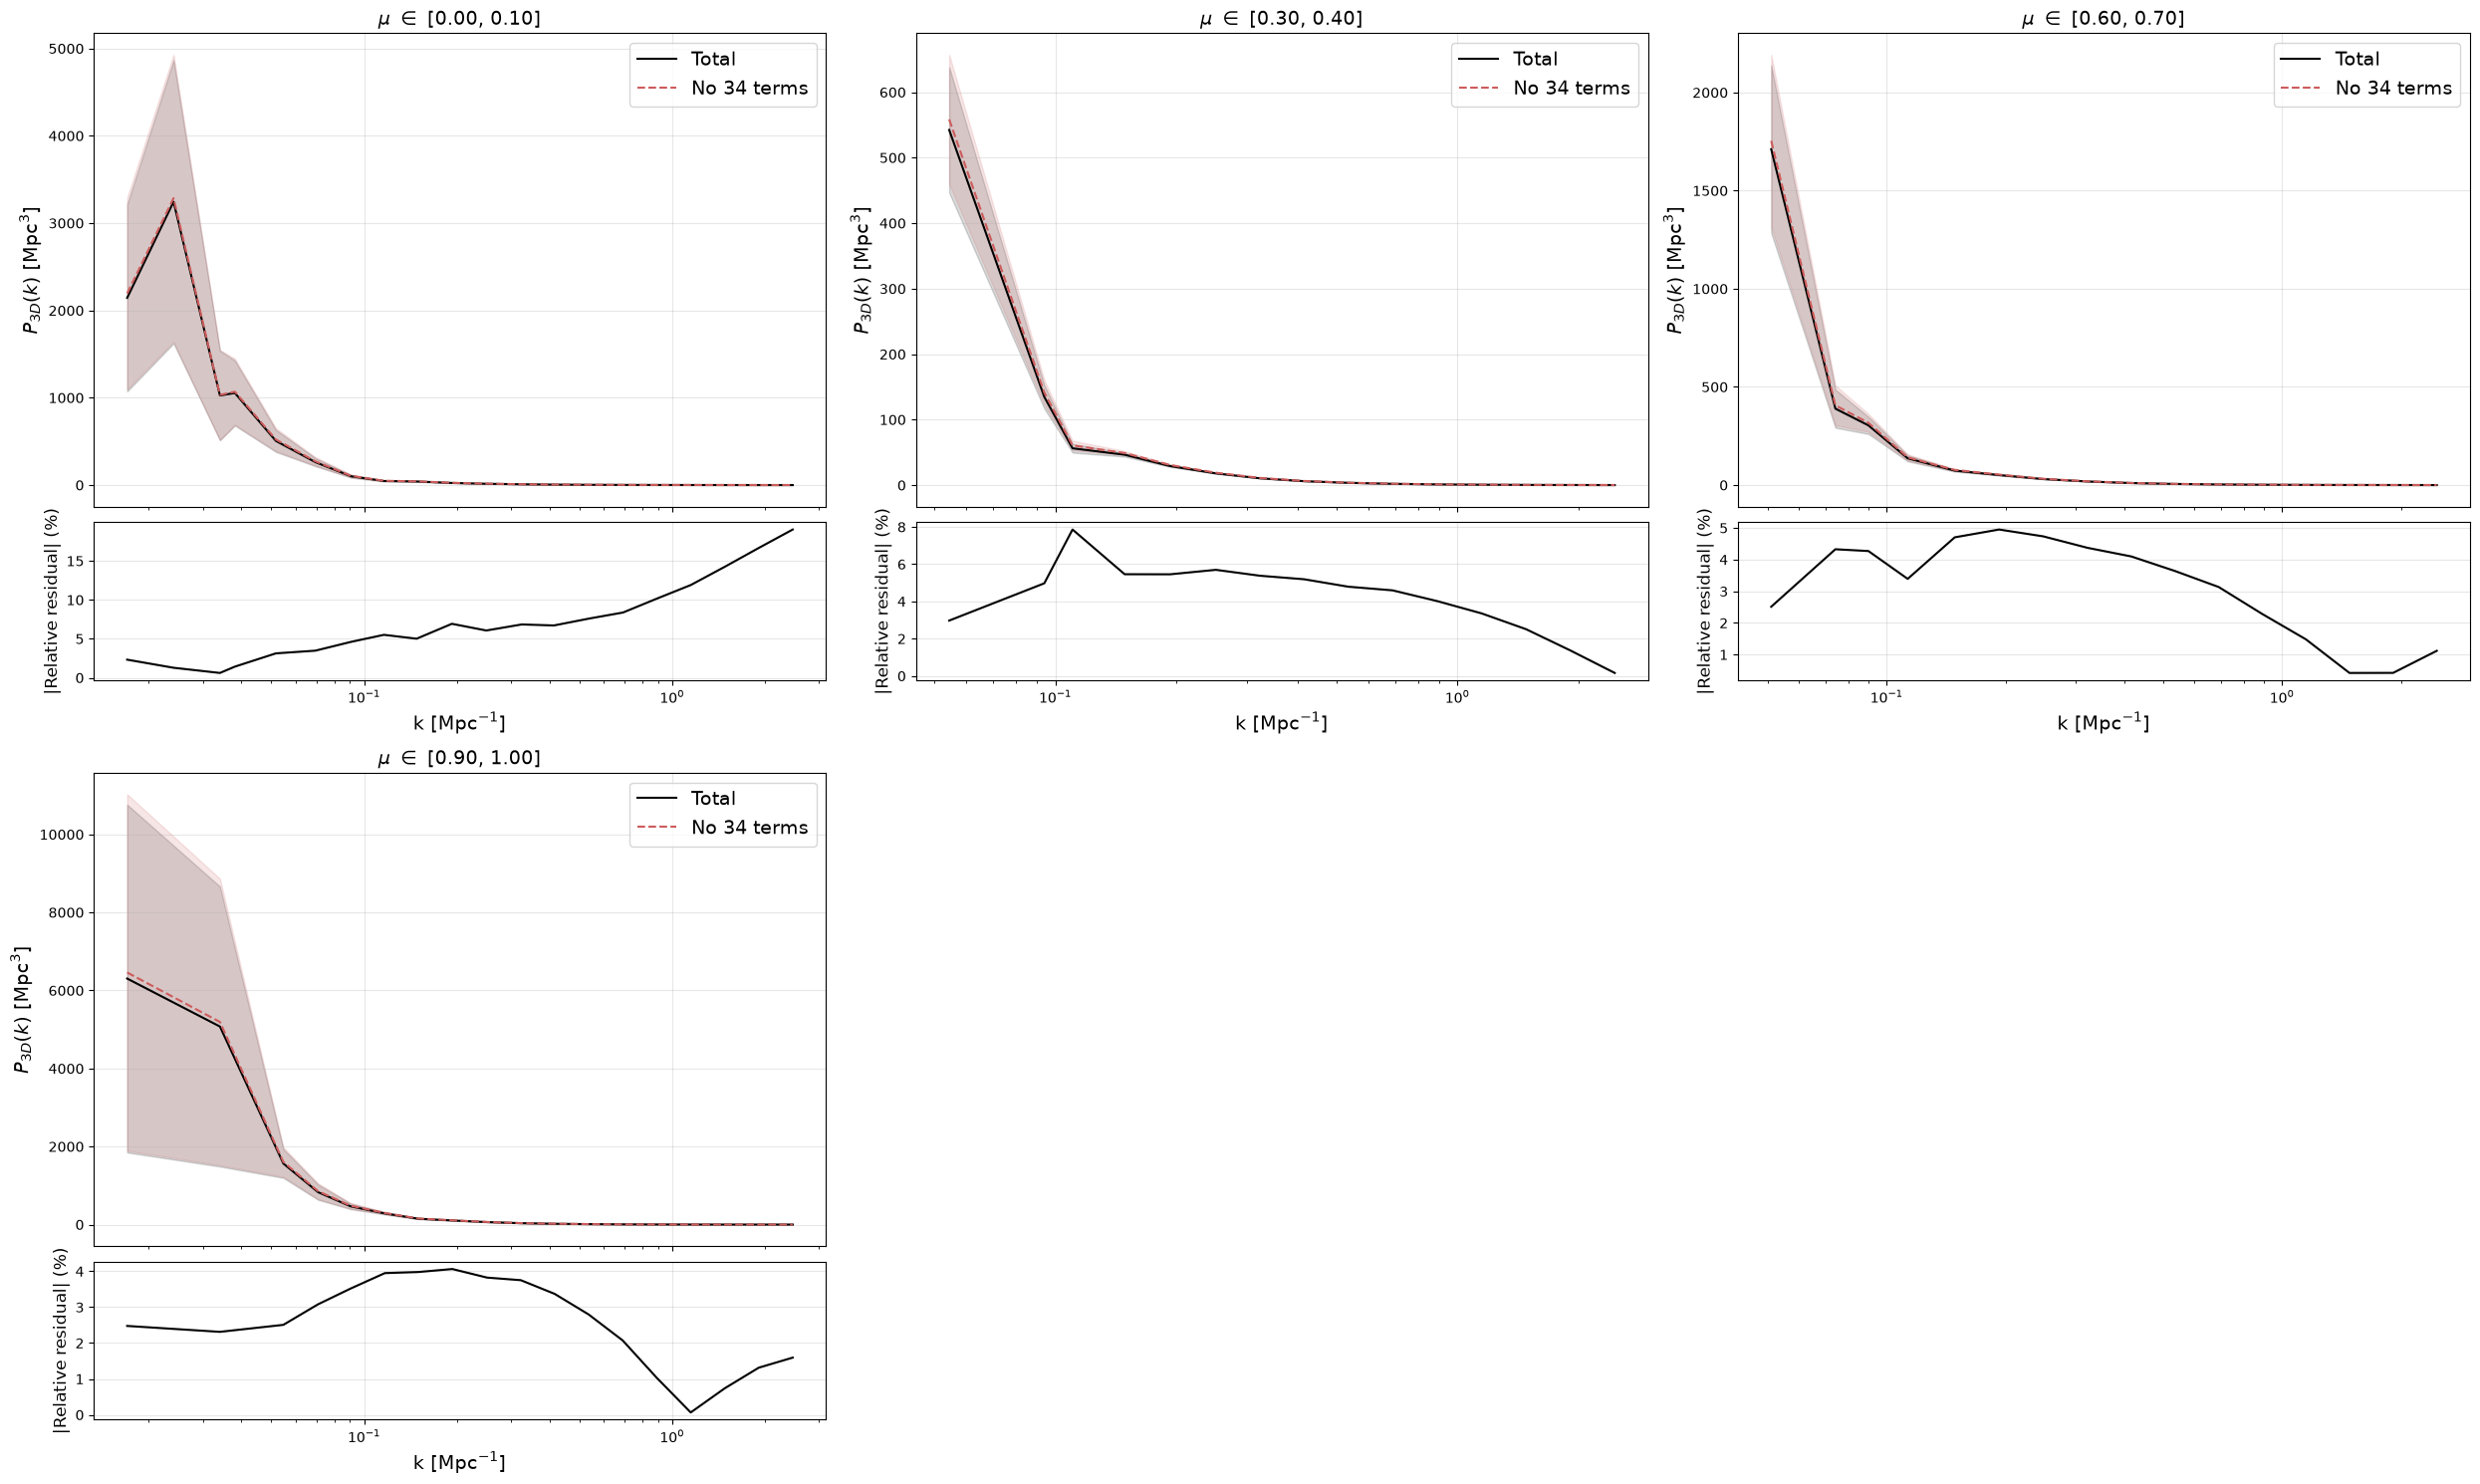

In [21]:
fig = plt.figure(figsize=(25, 15))
outer = fig.add_gridspec(2, 3)

for panel, i in enumerate(range(0, len(mu_center), 3)):
    inner = outer[panel].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.05)
    ax_main = fig.add_subplot(inner[0])
    ax_res = fig.add_subplot(inner[1], sharex=ax_main)

    mask = ~np.isnan(k[:, i])
    # ---------------- MAIN ----------------
    ax_main.plot(k[:, i][mask], P3d_tot[:, i][mask], color='k', label='Total')
    ax_main.fill_between(k[:, i][mask], P3d_tot[:, i][mask] - P3d_std_tot[:, i][mask], P3d_tot[:, i][mask] + P3d_std_tot[:, i][mask], color='k', alpha=0.15)
    ax_main.plot(k[:, i][mask], P3d_aprox[:, i][mask], linestyle='--', color='indianred', label='No 34 terms')
    ax_main.fill_between(k[:, i][mask], P3d_aprox[:, i][mask] - P3d_std_aprox[:, i][mask], P3d_aprox[:, i][mask] + P3d_std_aprox[:, i][mask], color='indianred', alpha=0.15)

    ax_main.set_xscale('log')
    ax_main.grid(alpha=0.3)
    ax_main.legend(fontsize=14)
    ax_main.set_ylabel(r'$P_{3D}(k)$ [Mpc$^3$]', fontsize=14)
    ax_main.set_title(r'$\mu$ $\in$ [%.2f, %.2f]' % (mu_bins[i], mu_bins[i+1]), fontsize=14)
    ax_main.tick_params(labelbottom=False)

    # ---------------- RESIDUAL ----------------
    ax_res.plot(k[:, i][mask], np.abs(P3d_tot[:, i][mask] - P3d_aprox[:, i][mask])/P3d_tot[:, i][mask]*100, color='k')

    ax_res.set_xscale('log')
    ax_res.grid(alpha=0.3)
    ax_res.set_xlabel(r'k [Mpc$^{-1}$]', fontsize=14)
    ax_res.set_ylabel('|Relative residual| (%)', fontsize=12)

plt.tight_layout()
plt.savefig('plot.png', dpi=200, bbox_inches='tight')

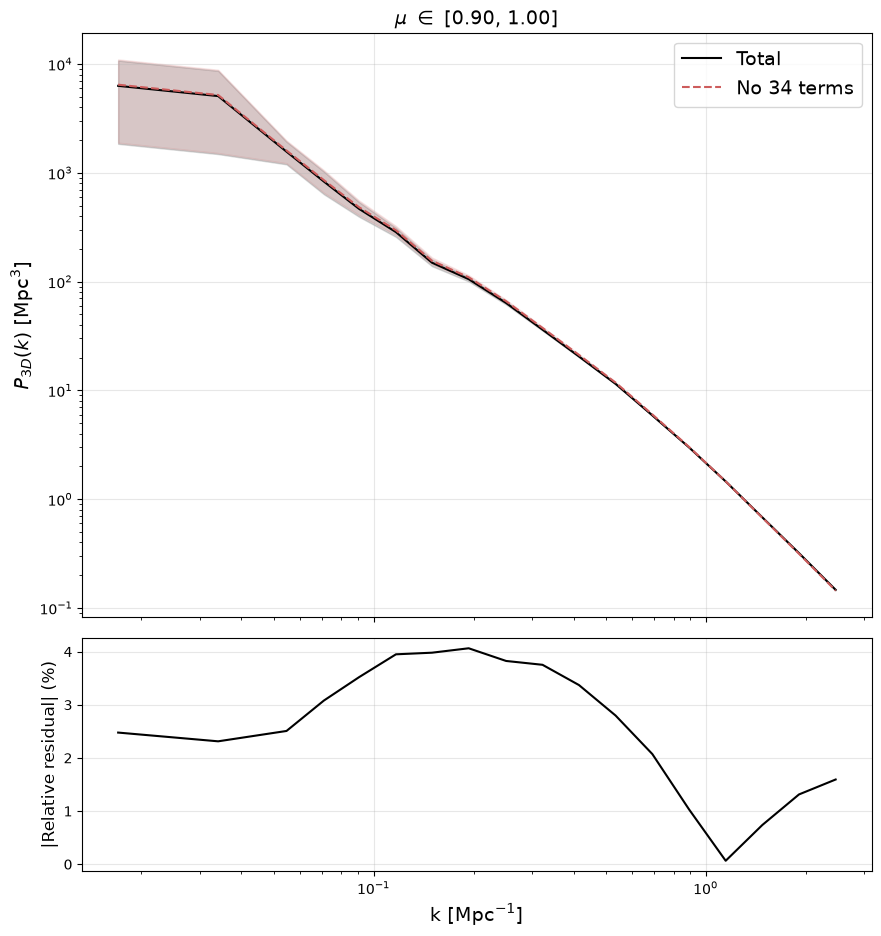

In [23]:
fig = plt.figure(figsize=(25, 18))

i = 9
gs = plt.GridSpec(2, 3)[0]
inner = gs.subgridspec(2, 1, height_ratios=[2.5, 1], hspace=0.05)
ax_main = fig.add_subplot(inner[0])
ax_res = fig.add_subplot(inner[1], sharex=ax_main)

mask = ~np.isnan(k[:, i])
# ---------------- MAIN ----------------
ax_main.plot(k[:, i][mask], P3d_tot[:, i][mask], color='k', label='Total')
ax_main.fill_between(k[:, i][mask], P3d_tot[:, i][mask] - P3d_std_tot[:, i][mask], P3d_tot[:, i][mask] + P3d_std_tot[:, i][mask], color='k', alpha=0.15)
ax_main.plot(k[:, i][mask], P3d_aprox[:, i][mask], linestyle='--', color='indianred', label='No 34 terms')
ax_main.fill_between(k[:, i][mask], P3d_aprox[:, i][mask] - P3d_std_aprox[:, i][mask], P3d_aprox[:, i][mask] + P3d_std_aprox[:, i][mask], color='indianred', alpha=0.15)

ax_main.set_xscale('log')
ax_main.set_yscale('log')
ax_main.grid(alpha=0.3)
ax_main.legend(fontsize=14)
ax_main.set_ylabel(r'$P_{3D}(k)$ [Mpc$^3$]', fontsize=14)
ax_main.set_title(r'$\mu$ $\in$ [%.2f, %.2f]' % (mu_bins[i], mu_bins[i+1]), fontsize=14)
ax_main.tick_params(labelbottom=False)

    # ---------------- RESIDUAL ----------------
ax_res.plot(k[:, i][mask], np.abs(P3d_tot[:, i][mask] - P3d_aprox[:, i][mask])/P3d_tot[:, i][mask]*100, color='k')

ax_res.set_xscale('log')
ax_res.grid(alpha=0.3)
ax_res.set_xlabel(r'k [Mpc$^{-1}$]', fontsize=14)
ax_res.set_ylabel('|Relative residual| (%)', fontsize=12)

plt.tight_layout()
plt.savefig('images/p3d_34.png', dpi=200, bbox_inches='tight')

## Measuring b_lya

In [7]:
import sys
import os
sys.path.append(os.path.abspath("../MW11model"))
from utils import Cosmologies

cosmo = Cosmologies().get_cosmo('ASTRID')
plin = cosmo.get_linP_Mpc(2.5, k)

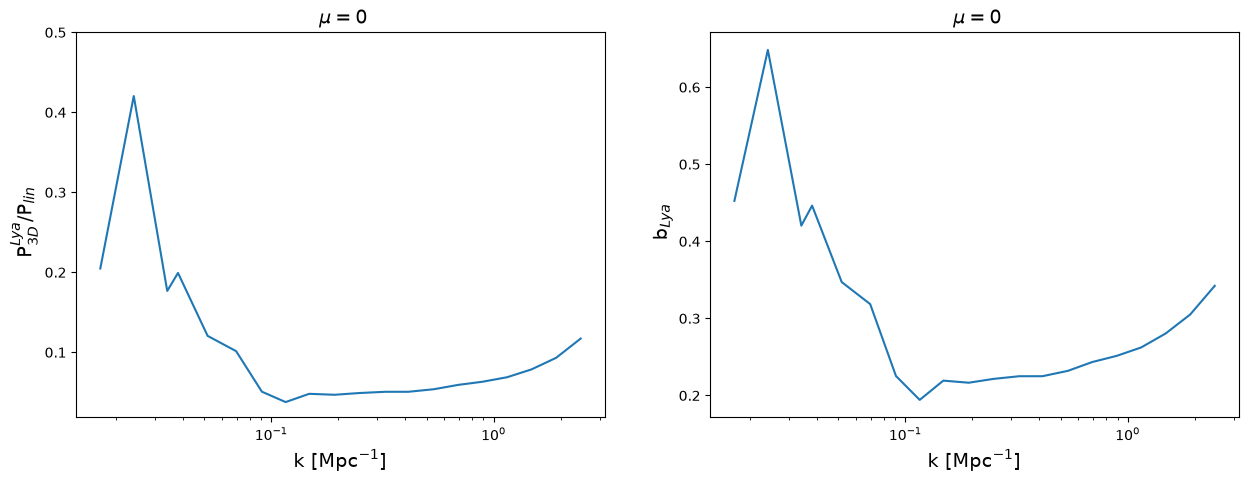

In [30]:
plt.figure(figsize=(15, 5))

i = 0  # mu = 0
plt.subplot(1, 2, 1)
plt.plot(k[:, i], P3d_lya[:, i]/plin[:, i])
plt.xscale('log')
plt.ylim(top=0.5)
plt.xlabel(r'k [Mpc$^{-1}$]', fontsize=14)
plt.ylabel(r' P$_{3D}^{Lya}$/P$_{lin}$', fontsize=14)
plt.title(r' $\mu = 0$', fontsize=14)

plt.subplot(1, 2, 2)
plt.plot(k[:, i], np.sqrt(P3d_lya[:, i]/plin[:, i]))
plt.xscale('log')
plt.xlabel(r'k [Mpc$^{-1}$]', fontsize=14)
plt.ylabel(r' b$_{Lya}$', fontsize=14)
plt.title(r' $\mu = 0$', fontsize=14);

In [34]:
np.sqrt(0.19)

np.float64(0.43588989435406733)

In [32]:
np.mean(np.sqrt(P3d_lya[:, 0]/plin[:, 0]))

np.float64(0.30386908445069954)

Something is wrong for sure